# F4.3 — Atribución espacial y espectral

**Procedencia.**
- **Parte GPU** (cascada de cordura y ablación espectral, solo `val`): `src/fase4/atribucion_gpu.py` en Kaggle (T4), commit `660985c` (`results/f43_atribucion/gpu/`).
- **Parte local** (agregación, constantes, perfiles, terciles, permutación y Holm, cordura por datos, cosenos, lectura de los ViT): `src/fase4/atribucion_local.py` en Kaggle (CPU), commit `9581304`, una sola vez (`results/f43_atribucion/local/`). Se corrió en Kaggle porque la prueba acotada local estimó ≈ 43 min (P20; `results/f43_atribucion/estimacion_local/estimacion.json`).
- Resoluciones P1–P20: `results/f43_atribucion/resoluciones.json`.
- Este notebook **no hace inferencia ni recalcula mapas**: dibuja las salidas versionadas y comprueba que las cifras citadas coinciden con `results/canonical_numbers.json` (`f43.*`).

**G1/G2.** La cascada, la ablación, la permutación y la cordura por datos que deciden son de `val`. Las figuras de prueba son réplica descriptiva con los mapas archivados de F3.7, después del commit del veredicto de la Fase 5.

**Regla de lectura** (`docs/plan_fase4.md`, F4.3, «qué se afirma / qué no»).
- Un mapa no prueba que la región sea necesaria; para eso está la ablación.
- En los ViT congelados, la lectura de los mapas sigue la tabla «Lectura de los ViT» del plan (sección 6).
- ΔF1 negativo en una banda (`val`) dice que el modelo depende de esa banda; nada sobre contenido emocional ni sobre prueba (G2).

In [1]:
%matplotlib inline
import hashlib
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():
    REPO = REPO.parent
for p in (REPO, REPO / 'src'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from viz import style
from src.fase4 import atribucion_comun as ac

style.apply()
D = REPO / 'results' / 'f43_atribucion'
FIG = D / 'figures'
LOC = json.loads((D / 'local' / 'resultados.json').read_text(encoding='utf-8'))
R = LOC['resultados']
CAS = json.loads((D / 'gpu' / 'cascada.json').read_text(encoding='utf-8'))
ABL = json.loads((D / 'gpu' / 'ablacion.json').read_text(encoding='utf-8'))
GMETA = json.loads((D / 'gpu' / 'atribucion_gpu_meta.json').read_text(encoding='utf-8'))
MED = np.load(D / 'local' / 'medias_clase.npz')
CANON = json.loads((REPO / 'results' / 'canonical_numbers.json').read_text(encoding='utf-8'))['numbers']
TECHS = ('gray_scott', 'perlin', 'lorenz')
SEEDS = ('42', '7', '123', '2024', '99')
CLASE = {0: 'No depresivo', 1: 'Depresivo'}
SEQ = 'magma'
FIGS = []


def pie(fig, text, y=-0.02, x=0.01):
    fig.text(x, y, text, ha='left', va='top', fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY, wrap=True)


def guardar(fig, nombre, descripcion):
    path = style.save(fig, FIG / nombre)
    FIGS.append({'archivo': path.relative_to(REPO).as_posix(), 'figura': descripcion})
    plt.show()
    return path


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def canon_val(nid, split='val'):
    v = CANON[nid]['value']
    return v[split] if isinstance(v, dict) else v


def ident(prefix):
    ks = [k[len(prefix) + 1:] for k in CANON if k.startswith(prefix + '.')]
    assert len(ks) == 1, (prefix, ks)
    return ks[0]


def sin_ejes(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

## 0. Procedencia y hashes

In [2]:
M = LOC['meta']
assert GMETA['git_commit'] == CAS['meta']['git_commit'] == ABL['meta']['git_commit']
assert not GMETA['smoke'] and not CAS['meta']['smoke'] and not ABL['meta']['smoke'] and GMETA['split'] == 'val'
assert M['cascada']['sha256'] == sha(D / 'gpu' / 'cascada.json')
assert sha(D / 'local' / 'medias_clase.npz') == M['medias_clase_sha256']
rows = [('Parte GPU — commit (atribucion_gpu_meta.json)', GMETA['git_commit']),
        ('Parte GPU — smoke / split / GPU', f"{GMETA['smoke']} / {GMETA['split']} / {GMETA['gpu']}"),
        ('Parte GPU — segundos', GMETA['segundos_total']),
        ('Parte local — commit (resultados.json:meta.git_commit)', M['git_commit']),
        ('Parte local — segundos', M['segundos']),
        ('Parte local — artefactos verificados (30 .npz + 20 .pt)', len(M['artefactos_verificados'])),
        ('Resoluciones (archivo · sha256)', f"{M['resoluciones']['archivo']} · {M['resoluciones']['sha256']}"),
        ('Resoluciones (sha256 en la parte GPU)', GMETA['resoluciones']['sha256']),
        ('cascada.json — sha256 (= meta.cascada de la parte local)', M['cascada']['sha256']),
        ('ablacion.json — sha256', sha(D / 'gpu' / 'ablacion.json')),
        ('medias_clase.npz — sha256', M['medias_clase_sha256'])]
pd.set_option('display.max_colwidth', 120)
pd.DataFrame(rows, columns=['concepto', 'valor'])

,concepto,valor
0,Parte GPU — commit (atribucion_gpu_meta.json),660985c36d1f118b166428c247c903670f946ca4
1,Parte GPU — smoke / split / GPU,False / val / Tesla T4
2,Parte GPU — segundos,1673.0
3,Parte local — commit (resultados.json:meta.git_commit),95813042a618ae3097bec3a80aef8683004475d4
4,Parte local — segundos,112.7
5,Parte local — artefactos verificados (30 .npz + 20 .pt),50
6,Resoluciones (archivo · sha256),results/f43_atribucion/resoluciones.json · 8aaf15614683cefb4304d4858f5dd5a93f060ccf042ab1553610412ad97e9961
7,Resoluciones (sha256 en la parte GPU),8aaf15614683cefb4304d4858f5dd5a93f060ccf042ab1553610412ad97e9961
8,cascada.json — sha256 (= meta.cascada de la parte local),cd1e61b198acfc7bab200067f509a65a19d264ca3d3881ea7f51822be56423d4
9,ablacion.json — sha256,f0d9774c172ef556df96a732d5823bcbdddbfdab7cf7fc386d3ef1738a220d58


In [3]:
pd.DataFrame([{'resolución': k, 'valor': v} for k, v in R['resoluciones'].items()])

,resolución,valor
0,clase_predicha,yhat_media_5_semillas
1,escala_entre_semillas,dividir_media_semilla
2,umbral_constantes_unidad,agrupado
3,l2_resolucion,56
4,perm_p,k_mas_1_sobre_B_mas_1
5,perm_rng,por_tecnica
6,similitud_constantes,excluir
7,sobre_maximo,como_dentro
8,criterio_semillas,mayoria
9,ssim_resolucion,56


## 1. Mapas medios por clase y su diferencia (`val`, clase real)

Agregación principal: `map_raw · map_raw_scale` sin normalizar, cada semilla dividida por su media en `val` (`escala_entre_semillas = dividir_media_semilla`), media entre semillas por muestra y luego por clase. Se muestran a 56 × 56 (`medias_clase.npz`). Clase 0 y clase 1 comparten escala por técnica; la diferencia (1 − 0) usa una escala divergente centrada en 0. La norma L2 es el estadístico de la prueba de permutación (sección 4).

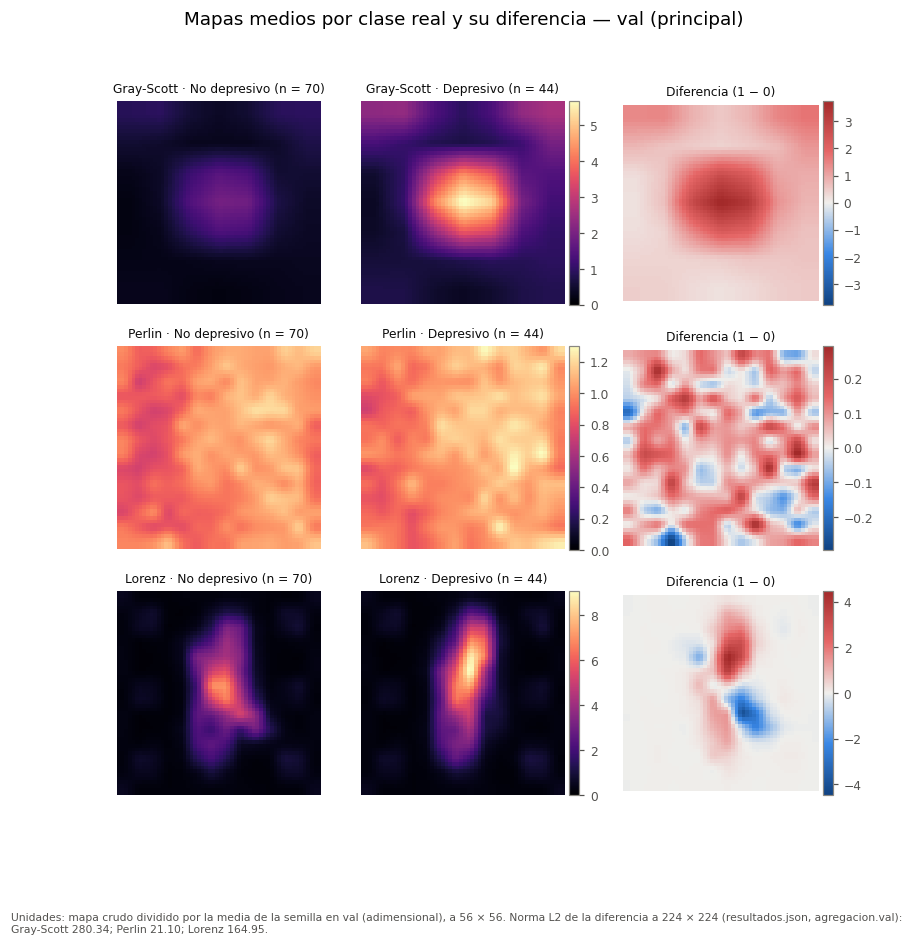

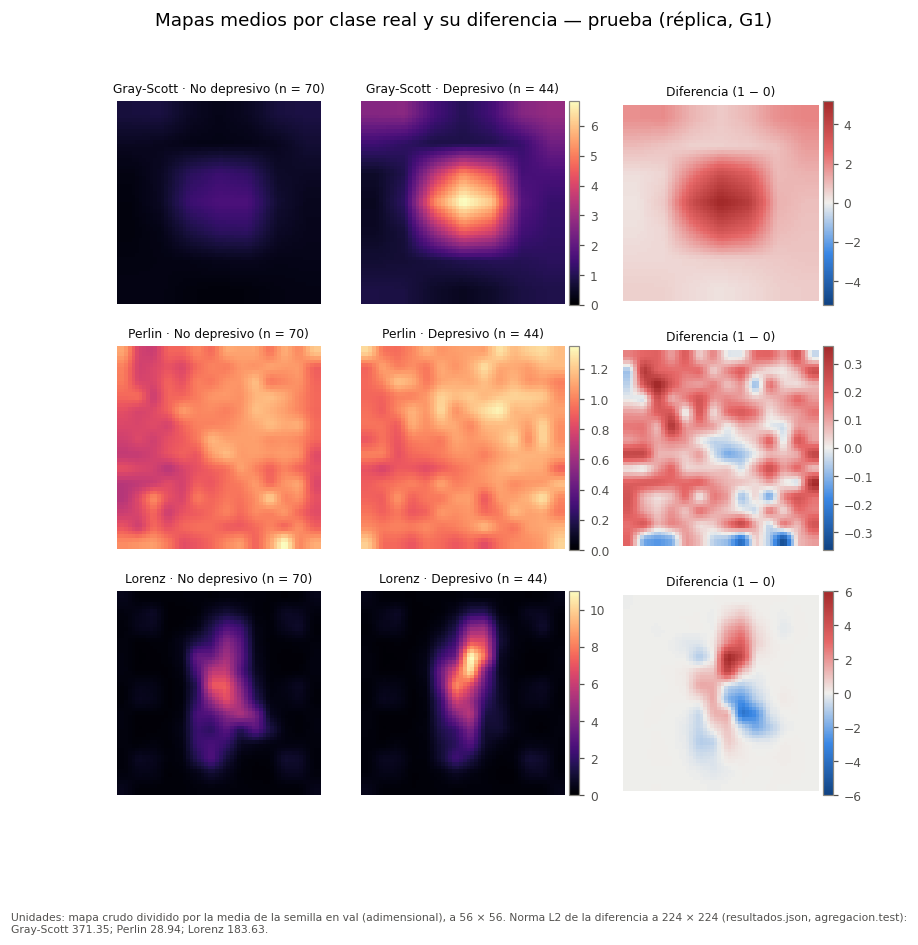

In [4]:
def fila_mapas(axes, t, clave, split):
    m0, m1 = MED[f'{t}|{clave}|{split}|real|y0'], MED[f'{t}|{clave}|{split}|real|y1']
    vmax = max(m0.max(), m1.max())
    for ax, m, y in ((axes[0], m0, 0), (axes[1], m1, 1)):
        im = ax.imshow(m, cmap=SEQ, vmin=0, vmax=vmax)
        n = R['tecnicas'][t]['agregacion'][split]['n_por_clase_real'][str(y)]
        ax.set_title(f'{style.TECH_LABEL[t]} · {CLASE[y]} (n = {n})', fontsize=style.FONT_SIZES['annot'] + 1)
        sin_ejes(ax)
    plt.colorbar(im, ax=axes[:2], fraction=0.025, pad=0.01)
    d = m1 - m0
    lim = np.abs(d).max()
    im = axes[2].imshow(d, cmap=style.DIVERGING, vmin=-lim, vmax=lim)
    axes[2].set_title(f'Diferencia (1 − 0)', fontsize=style.FONT_SIZES['annot'] + 1)
    sin_ejes(axes[2])
    plt.colorbar(im, ax=axes[2], fraction=0.05, pad=0.02)


for split, nombre, etiqueta in (('val', 'f43_01_mapas_medios_val', 'val (principal)'),
                                ('test', 'f43_02_mapas_medios_prueba_replica', 'prueba (réplica, G1)')):
    fig, axes = plt.subplots(3, 3, figsize=(8.4, 8.2))
    for i, t in enumerate(TECHS):
        fila_mapas(axes[i], t, 'map', split)
    fig.suptitle(f'Mapas medios por clase real y su diferencia — {etiqueta}')
    l2 = {t: R['tecnicas'][t]['agregacion'][split]['norma_l2_diferencia_real'] for t in TECHS}
    pie(fig, 'Unidades: mapa crudo dividido por la media de la semilla en val (adimensional), a 56 × 56. '
             'Norma L2 de la diferencia a 224 × 224 (resultados.json, agregacion.' + split + '): '
             + '; '.join(f'{style.TECH_LABEL[t]} {v:.2f}' for t, v in l2.items()) + '.')
    guardar(fig, nombre, f'Mapas medios por clase real y diferencia, {etiqueta}')

### 1.1 Mapas medios por clase predicha (secundaria, `val`) y atención del *backbone* (ViT)

La clase predicha es ŷ = 1[media de `p_dep` de las 5 semillas > 0.5] (`clase_predicha = yhat_media_5_semillas`). El mapa del *backbone* (`backbone_map`) es la atención del ViT de ImageNet, idéntica entre semillas.

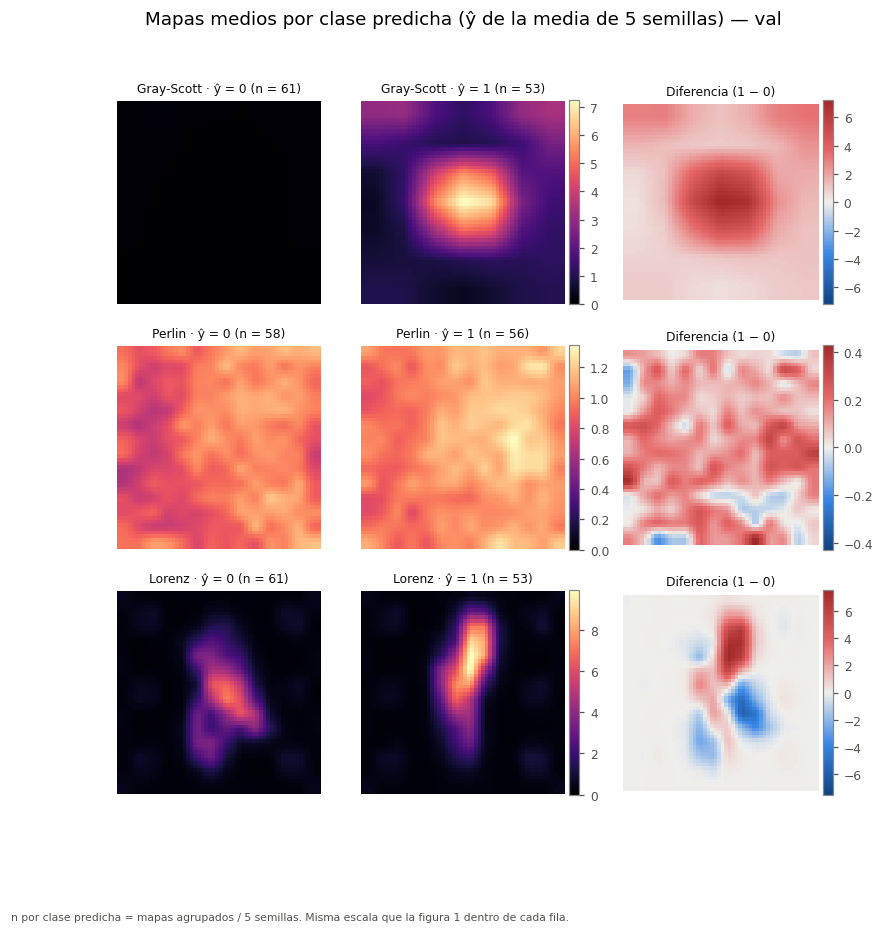

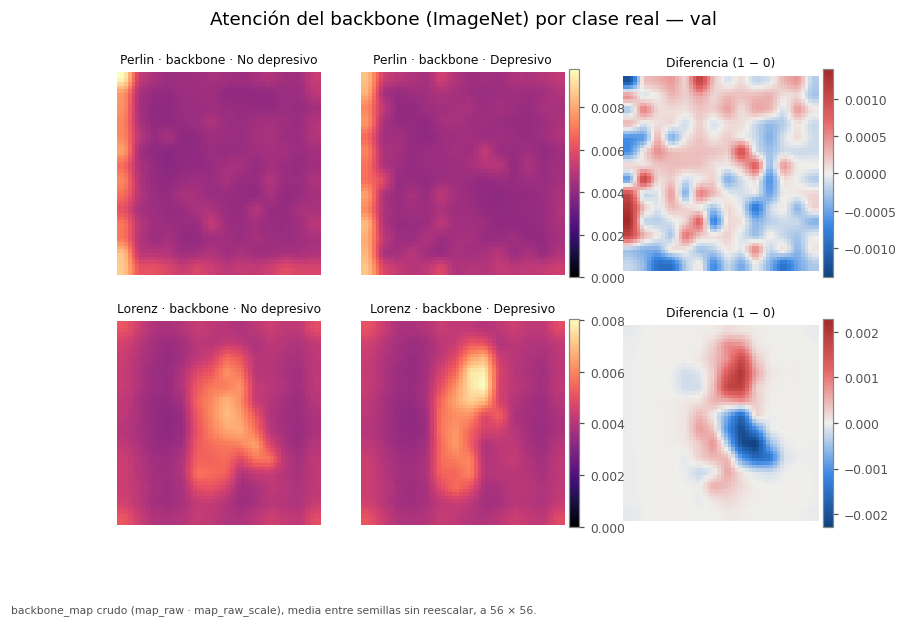

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f43_atribucion/figures/f43_04_backbone_por_clase_val.png')

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(8.4, 8.2))
for i, t in enumerate(TECHS):
    m0, m1 = MED[f'{t}|map|val|predicha|y0'], MED[f'{t}|map|val|predicha|y1']
    vmax = max(m0.max(), m1.max())
    n = R['tecnicas'][t]['agregacion']['val']['constantes_clase_predicha']['agrupada']
    for ax, m, y in ((axes[i, 0], m0, 0), (axes[i, 1], m1, 1)):
        im = ax.imshow(m, cmap=SEQ, vmin=0, vmax=vmax)
        ax.set_title(f'{style.TECH_LABEL[t]} · ŷ = {y} (n = {n[str(y)]["n"] // 5})', fontsize=style.FONT_SIZES['annot'] + 1)
        sin_ejes(ax)
    plt.colorbar(im, ax=axes[i, :2], fraction=0.025, pad=0.01)
    d = m1 - m0
    lim = np.abs(d).max()
    im = axes[i, 2].imshow(d, cmap=style.DIVERGING, vmin=-lim, vmax=lim)
    axes[i, 2].set_title('Diferencia (1 − 0)', fontsize=style.FONT_SIZES['annot'] + 1)
    sin_ejes(axes[i, 2])
    plt.colorbar(im, ax=axes[i, 2], fraction=0.05, pad=0.02)
fig.suptitle('Mapas medios por clase predicha (ŷ de la media de 5 semillas) — val')
pie(fig, 'n por clase predicha = mapas agrupados / 5 semillas. Misma escala que la figura 1 dentro de cada fila.')
guardar(fig, 'f43_03_mapas_medios_predicha_val', 'Mapas medios por clase predicha, val')

fig, axes = plt.subplots(2, 3, figsize=(8.4, 5.4))
for i, t in enumerate(('perlin', 'lorenz')):
    m0, m1 = MED[f'{t}|backbone_map|val|real|y0'], MED[f'{t}|backbone_map|val|real|y1']
    vmax = max(m0.max(), m1.max())
    for ax, m, y in ((axes[i, 0], m0, 0), (axes[i, 1], m1, 1)):
        im = ax.imshow(m, cmap=SEQ, vmin=0, vmax=vmax)
        ax.set_title(f'{style.TECH_LABEL[t]} · backbone · {CLASE[y]}', fontsize=style.FONT_SIZES['annot'] + 1)
        sin_ejes(ax)
    plt.colorbar(im, ax=axes[i, :2], fraction=0.025, pad=0.01)
    d = m1 - m0
    lim = np.abs(d).max()
    im = axes[i, 2].imshow(d, cmap=style.DIVERGING, vmin=-lim, vmax=lim)
    axes[i, 2].set_title('Diferencia (1 − 0)', fontsize=style.FONT_SIZES['annot'] + 1)
    sin_ejes(axes[i, 2])
    plt.colorbar(im, ax=axes[i, 2], fraction=0.05, pad=0.02)
fig.suptitle('Atención del backbone (ImageNet) por clase real — val')
pie(fig, 'backbone_map crudo (map_raw · map_raw_scale), media entre semillas sin reescalar, a 56 × 56.')
guardar(fig, 'f43_04_backbone_por_clase_val', 'Atención del backbone ViT por clase real, val')

## 2. Gray-Scott: perfil radial

28 anillos de 4 px desde el centro (111.5, 111.5) de la imagen de 224 px, sobre los mapas medios por clase real (`agregacion.<split>.perfil_radial`). `val` es el principal; prueba, réplica.

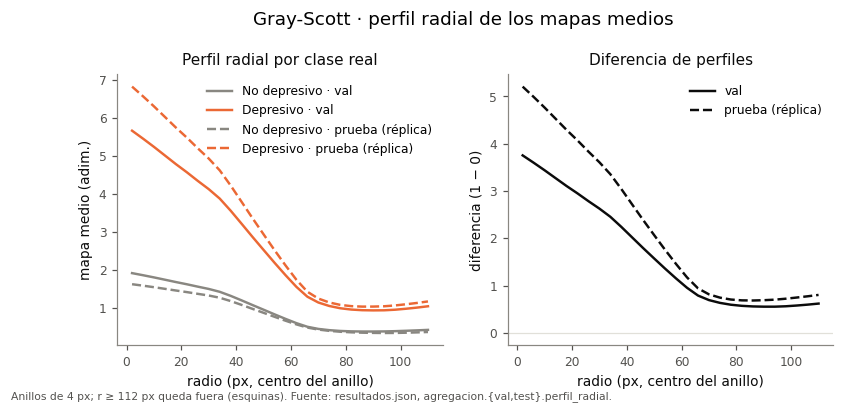

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f43_atribucion/figures/f43_05_gray_scott_perfil_radial.png')

In [6]:
P = {sp: R['tecnicas']['gray_scott']['agregacion'][sp]['perfil_radial'] for sp in ('val', 'test')}
r = (np.arange(P['val']['anillos']['n']) + 0.5) * P['val']['anillos']['ancho_px']
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.2))
for sp, ls, et in (('val', '-', 'val'), ('test', '--', 'prueba (réplica)')):
    for y, col in ((0, style.MUTED), (1, style.TECH_COLOR['gray_scott'])):
        axes[0].plot(r, P[sp]['clase_real'][str(y)], ls=ls, color=col, label=f'{CLASE[y]} · {et}')
    axes[1].plot(r, P[sp]['diferencia_real'], ls=ls, color=style.INK, label=et)
axes[0].set(xlabel='radio (px, centro del anillo)', ylabel='mapa medio (adim.)', title='Perfil radial por clase real')
axes[1].axhline(0, color=style.GRID, lw=0.8)
axes[1].set(xlabel='radio (px, centro del anillo)', ylabel='diferencia (1 − 0)', title='Diferencia de perfiles')
axes[0].legend(); axes[1].legend()
fig.suptitle('Gray-Scott · perfil radial de los mapas medios', y=1.06)
pie(fig, 'Anillos de 4 px; r ≥ 112 px queda fuera (esquinas). Fuente: resultados.json, agregacion.{val,test}.perfil_radial.')
guardar(fig, 'f43_05_gray_scott_perfil_radial', 'Gray-Scott, perfil radial por clase real')

## 3. Lorenz: mapas por tercil de u4

Cortes de los terciles en `train` (`terciles_u4.cortes_train`); en cada tercil, mapas medios por clase real en `val`. El conteo por celda está en el título; con pocos mapas, la media es ruidosa (descriptivo).

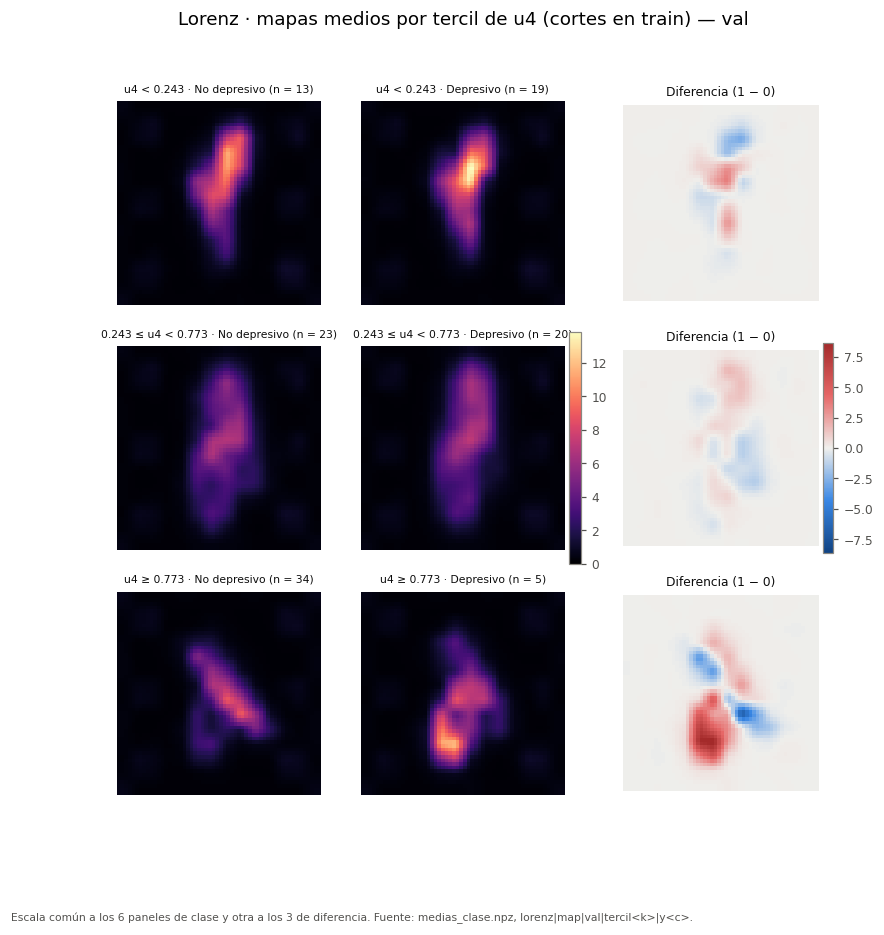

,tercil,n clase 0,n clase 1
0,u4 < 0.243,13,19
1,0.243 ≤ u4 < 0.773,23,20
2,u4 ≥ 0.773,34,5


In [7]:
T = R['tecnicas']['lorenz']['agregacion']['val']['terciles_u4']
fig, axes = plt.subplots(3, 3, figsize=(8.4, 8.2))
c = T['cortes_train']
rangos = [f'u4 < {c[0]:.3f}', f'{c[0]:.3f} ≤ u4 < {c[1]:.3f}', f'u4 ≥ {c[1]:.3f}']
vmax = max(MED[f'lorenz|map|val|tercil{k}|y{y}'].max() for k in range(3) for y in (0, 1))
dl = max(np.abs(MED[f'lorenz|map|val|tercil{k}|y1'] - MED[f'lorenz|map|val|tercil{k}|y0']).max() for k in range(3))
for k in range(3):
    for y in (0, 1):
        ax = axes[k, y]
        im = ax.imshow(MED[f'lorenz|map|val|tercil{k}|y{y}'], cmap=SEQ, vmin=0, vmax=vmax)
        ax.set_title(f'{rangos[k]} · {CLASE[y]} (n = {T["conteos"][str(k)][str(y)]})', fontsize=style.FONT_SIZES['annot'])
        sin_ejes(ax)
    im2 = axes[k, 2].imshow(MED[f'lorenz|map|val|tercil{k}|y1'] - MED[f'lorenz|map|val|tercil{k}|y0'],
                            cmap=style.DIVERGING, vmin=-dl, vmax=dl)
    axes[k, 2].set_title('Diferencia (1 − 0)', fontsize=style.FONT_SIZES['annot'] + 1)
    sin_ejes(axes[k, 2])
plt.colorbar(im, ax=axes[:, :2], fraction=0.025, pad=0.01)
plt.colorbar(im2, ax=axes[:, 2], fraction=0.05, pad=0.02)
fig.suptitle('Lorenz · mapas medios por tercil de u4 (cortes en train) — val')
pie(fig, 'Escala común a los 6 paneles de clase y otra a los 3 de diferencia. Fuente: medias_clase.npz, lorenz|map|val|tercil<k>|y<c>.')
guardar(fig, 'f43_06_lorenz_terciles_u4', 'Lorenz, mapas por tercil de u4, val')
pd.DataFrame([{'tercil': rangos[k], 'n clase 0': T['conteos'][str(k)]['0'], 'n clase 1': T['conteos'][str(k)]['1']} for k in range(3)])

## 4. Prueba de permutación y Holm (`val`, m = 3)

Estadístico: ‖media(y=1) − media(y=0)‖₂ de los mapas de `val` a 56 × 56; 5,000 permutaciones de etiquetas con `default_rng(2026)` por técnica; p = (k + 1)/(B + 1).

In [8]:
H = R['holm']['familia']
rows = []
for t in TECHS:
    pv = R['tecnicas'][t]['permutacion_val']
    assert canon_val(f'f43.{t}.permutacion.p') == pv['p'] and canon_val(f'f43.{t}.permutacion.p_holm') == H[t]['p_holm']
    rows.append({'técnica': style.TECH_LABEL[t], 'L2 observado': pv['t_obs'], 'media nula': pv['perm_media'],
                 'DE nula': pv['perm_de'], 'k': pv['k'], 'B': pv['B'], 'p': pv['p'], 'p ajustado (Holm)': H[t]['p_holm'],
                 'rango': H[t]['rank'], 'α_h': H[t]['alpha_h'], 'rechaza H0': H[t]['reject']})
pd.DataFrame(rows)

,técnica,L2 observado,media nula,DE nula,k,B,p,p ajustado (Holm),rango,α_h,rechaza H0
0,Gray-Scott,70.061081,16.261998,10.456493,1,5000,0.000400,0.000800,2,0.025000,True
1,Perlin,5.237606,4.415383,0.397634,177,5000,0.035593,0.035593,3,0.050000,True
2,Lorenz,41.049595,13.179091,4.354045,0,5000,0.000200,0.000600,1,0.016667,True


## 5. Cascada de cordura por parámetros (`val`)

Por paso (acumulativo desde la salida), mediana por muestra del Spearman a 56 × 56 entre el mapa del modelo aleatorizado y el original, una línea por semilla. La banda gris es el rango de los 10 pares de semillas reales (criterio relativo): debajo de su mínimo, «cambia». Regla de P9: un mapa no constante que se vuelve constante cuenta como cambio (Spearman imputado −1 antes de la mediana); los mapas que ya eran constantes se excluyen. En Gray-Scott se muestra solo `map`; en los ViT, `map` y `backbone_map`.

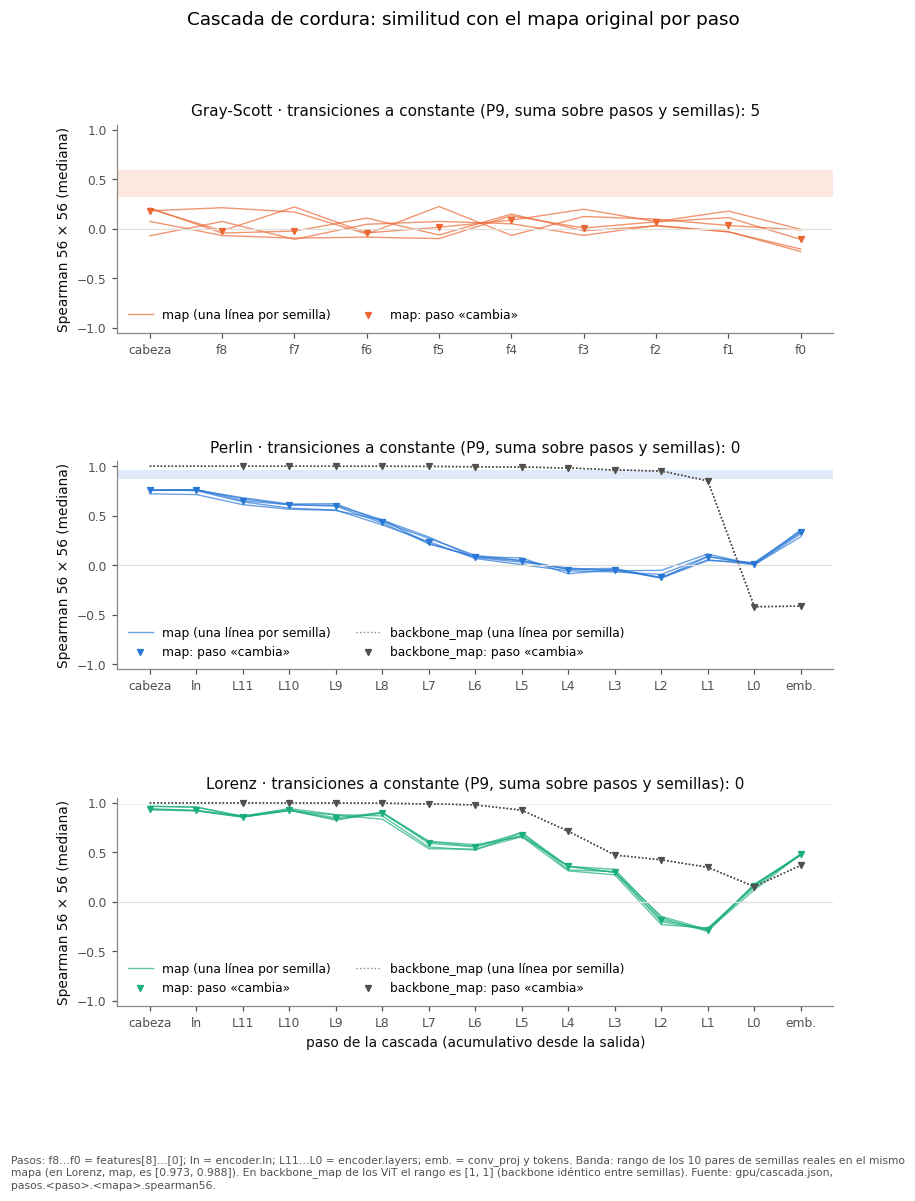

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f43_atribucion/figures/f43_07_cascada_por_paso.png')

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(8.4, 10.4), gridspec_kw={'hspace': 0.62})
for ax, t in zip(axes, TECHS):
    x = CAS['tecnicas'][t]
    orden = x['orden']
    kinds = [k for k in ('map', 'backbone_map') if k in x['pasos']['cabeza']]
    for k in kinds:
        ref = x['pasos'][orden[0]][k]['spearman56']['rango_referencia']
        col = style.TECH_COLOR[t] if k == 'map' else style.INK_SECONDARY
        ax.axhspan(ref[0], ref[1], color=col, alpha=0.15, lw=0)
        vals = np.array([x['pasos'][p][k]['spearman56']['valores'] for p in orden])
        for j in range(vals.shape[1]):
            ax.plot(range(len(orden)), vals[:, j], color=col, lw=0.9, alpha=0.7, ls='-' if k == 'map' else ':',
                    label=(f'{k} (una línea por semilla)' if j == 0 else None))
        cambia = [x['pasos'][p][k]['spearman56']['global'] == 'cambia' for p in orden]
        ax.scatter([i for i, cb in enumerate(cambia) if cb], [np.median(vals[i]) for i, cb in enumerate(cambia) if cb],
                   marker='v', s=14, color=col, zorder=3, label=f'{k}: paso «cambia»')
    ax.set_xticks(range(len(orden)))
    ax.set_xticklabels([p.replace('encoder.layers.', 'L').replace('features.', 'f').replace('encoder.ln', 'ln').replace('embeddings', 'emb.') for p in orden], rotation=0)
    ax.set_ylim(-1.05, 1.05)
    ax.axhline(0, color=style.GRID, lw=0.8)
    ax.set_ylabel('Spearman 56 × 56 (mediana)')
    tr = CANON[f'f43.{t}.cascada.map.n_transiciones_a_constante']['value']
    ax.set_title(f'{style.TECH_LABEL[t]} · transiciones a constante (P9, suma sobre pasos y semillas): {tr}')
    ax.legend(loc='lower left', ncol=2)
axes[-1].set_xlabel('paso de la cascada (acumulativo desde la salida)')
fig.suptitle('Cascada de cordura: similitud con el mapa original por paso')
pie(fig, 'Pasos: f8…f0 = features[8]…[0]; ln = encoder.ln; L11…L0 = encoder.layers; emb. = conv_proj y tokens. Banda: rango de los 10 pares de semillas reales en el mismo mapa (en Lorenz, map, es [0.973, 0.988]). En backbone_map de los ViT el rango es [1, 1] '
         '(backbone idéntico entre semillas). Fuente: gpu/cascada.json, pasos.<paso>.<mapa>.spearman56.')
guardar(fig, 'f43_07_cascada_por_paso', 'Cascada de cordura por paso, Spearman 56 × 56, con banda de semillas reales')

In [10]:
rows = []
for t in TECHS:
    x = CAS['tecnicas'][t]
    for p in x['orden']:
        for k in [k for k in ('map', 'backbone_map') if k in x['pasos'][p]]:
            s = x['pasos'][p][k]
            det = {kk: v for kk, v in s['spearman56']['por_semilla_detalle'].items() if not kk.startswith('_')}
            rows.append({'técnica': style.TECH_LABEL[t], 'paso': p, 'mapa': k,
                         'Spearman (mediana de semillas)': float(np.median(s['spearman56']['valores'])),
                         'Spearman': s['spearman56']['global'], 'SSIM 56': s['ssim56']['global'], 'SSIM 224': s['ssim224']['global'],
                         'transiciones a constante': sum(d['n_transiciones_a_constante'] for d in det.values()),
                         'ya constantes (excluidos)': sum(d['n_base_constante'] for d in det.values())})
pd.set_option('display.max_rows', 100)
pd.DataFrame(rows)

,técnica,paso,mapa,Spearman (mediana de semillas),Spearman,SSIM 56,SSIM 224,transiciones a constante,ya constantes (excluidos)
0,Gray-Scott,cabeza,map,0.180431,cambia,cambia,cambia,0,62
1,Gray-Scott,features.8,map,-0.022202,cambia,cambia,cambia,3,62
2,Gray-Scott,features.7,map,-0.024141,cambia,cambia,cambia,0,62
3,Gray-Scott,features.6,map,-0.043196,cambia,cambia,cambia,2,62
4,Gray-Scott,features.5,map,0.014295,cambia,cambia,cambia,0,62
5,Gray-Scott,features.4,map,0.086279,cambia,cambia,cambia,0,62
6,Gray-Scott,features.3,map,0.007051,cambia,cambia,cambia,0,62
7,Gray-Scott,features.2,map,0.068929,cambia,cambia,cambia,0,62
8,Gray-Scott,features.1,map,0.031992,cambia,cambia,cambia,0,62
9,Gray-Scott,features.0,map,-0.109017,cambia,cambia,cambia,0,62


## 6. Cordura por aleatorización de datos, cosenos de cabezas y lectura de los ViT

Cordura por datos: Spearman 56 × 56 por muestra entre el mapa real (F3.5) y el del control permutado (F3.6) de la misma semilla, frente a los 10 pares de semillas reales. Cosenos: entre los pesos de la cabeza real y la permutada de la misma semilla (w1 y w1 − w0), frente a los 10 pares de cabezas reales; «alto» si cae en el rango, «bajo» si queda debajo de su mínimo. La lectura de los ViT usa `coseno_lectura = w1`.

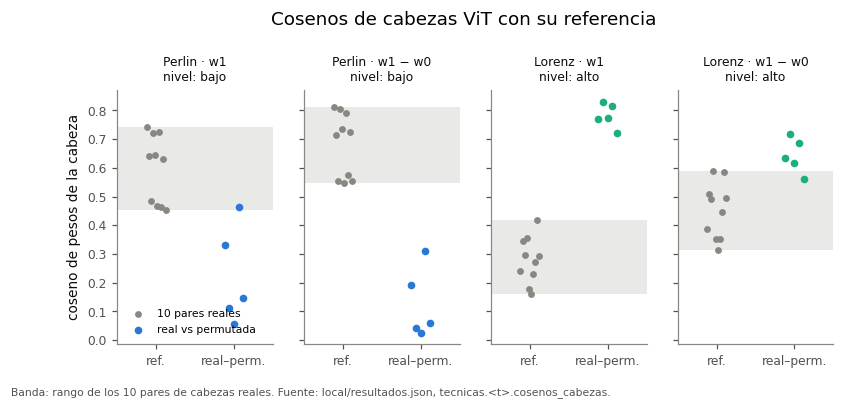

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f43_atribucion/figures/f43_08_cosenos_cabezas.png')

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(8.4, 3.0), sharey=True)
for j, (t, v) in enumerate([(t, v) for t in ('perlin', 'lorenz') for v in ('w1', 'w1_menos_w0')]):
    ax = axes[j]
    cz = R['tecnicas'][t]['cosenos_cabezas'][v]
    ref = list(cz['referencia'].values())
    ax.axhspan(*cz['rango_referencia'], color=style.MUTED, alpha=0.18, lw=0)
    ax.scatter(np.full(len(ref), 0.0) + np.linspace(-0.12, 0.12, len(ref)), ref, s=12, color=style.MUTED, label='10 pares reales')
    rp = [cz['real_vs_permutada'][s] for s in SEEDS]
    ax.scatter(np.full(5, 1.0) + np.linspace(-0.12, 0.12, 5), rp, s=16, color=style.TECH_COLOR[t], label='real vs permutada')
    ax.set_xticks([0, 1]); ax.set_xticklabels(['ref.', 'real–perm.'])
    ax.set_xlim(-0.5, 1.5)
    ax.set_title(f'{style.TECH_LABEL[t]} · {v.replace("_menos_", " − ")}\nnivel: {cz["nivel"]}', fontsize=style.FONT_SIZES['annot'] + 1)
    assert ident(f'f43.{t}.coseno.{v}.nivel') == cz['nivel']
axes[0].set_ylabel('coseno de pesos de la cabeza')
axes[0].legend(loc='lower left', fontsize=style.FONT_SIZES['annot'])
fig.suptitle('Cosenos de cabezas ViT con su referencia', y=1.12)
pie(fig, 'Banda: rango de los 10 pares de cabezas reales. Fuente: local/resultados.json, tecnicas.<t>.cosenos_cabezas.')
guardar(fig, 'f43_08_cosenos_cabezas', 'Cosenos de cabezas ViT real–permutada con referencia de 10 pares')

In [12]:
rows = []
for t in TECHS:
    for k in [k for k in ('map', 'backbone_map') if k in R['tecnicas'][t]['cordura_datos']]:
        for sp in ('val', 'test'):
            for med in ('spearman56', 'ssim'):
                c = R['tecnicas'][t]['cordura_datos'][k][sp][med]
                rows.append({'técnica': style.TECH_LABEL[t], 'mapa': k, 'split': sp if sp == 'val' else 'prueba (réplica)',
                             'medida': med, 'por semilla': ' '.join(f'{x:.3f}' for x in c['valores']),
                             'rango ref.': f"[{c['rango_referencia'][0]:.3f}, {c['rango_referencia'][1]:.3f}]",
                             'veredicto': c['global']})
pd.DataFrame(rows)

,técnica,mapa,split,medida,por semilla,rango ref.,veredicto
0,Gray-Scott,map,val,spearman56,0.239 0.204 -0.112 0.513 0.185,"[0.319, 0.591]",cambia
1,Gray-Scott,map,val,ssim,0.258 0.272 0.097 0.344 0.210,"[0.495, 0.716]",cambia
2,Gray-Scott,map,prueba (réplica),spearman56,0.193 0.266 0.053 0.453 0.189,"[0.237, 0.524]",cambia
3,Gray-Scott,map,prueba (réplica),ssim,0.278 0.285 0.146 0.319 0.202,"[0.485, 0.727]",cambia
4,Perlin,map,val,spearman56,0.827 0.773 0.733 0.840 0.764,"[0.874, 0.959]",cambia
5,Perlin,map,val,ssim,0.752 0.751 0.602 0.796 0.721,"[0.816, 0.923]",cambia
6,Perlin,map,prueba (réplica),spearman56,0.830 0.771 0.736 0.839 0.767,"[0.878, 0.959]",cambia
7,Perlin,map,prueba (réplica),ssim,0.770 0.773 0.623 0.796 0.730,"[0.821, 0.927]",cambia
8,Perlin,backbone_map,val,spearman56,1.000 1.000 1.000 1.000 1.000,"[1.000, 1.000]",no_cambia
9,Perlin,backbone_map,val,ssim,1.000 1.000 1.000 1.000 1.000,"[1.000, 1.000]",no_cambia


In [13]:
rows = []
for t, x in R['lectura_vit'].items():
    assert ident(f'f43.{t}.lectura_vit') == x['lectura']
    assert x['lectura'] == ac.lectura_vit(x['cordura_datos'], x['coseno'], x['cabeza_cascada'])
    rows.append({'técnica': style.TECH_LABEL[t], 'cordura por datos (map, Spearman, val)': x['cordura_datos'],
                 'coseno (w1)': x['coseno'], 'cascada, paso cabeza (map)': x['cabeza_cascada'], 'lectura': x['lectura']})
pd.DataFrame(rows)

,técnica,"cordura por datos (map, Spearman, val)",coseno (w1),"cascada, paso cabeza (map)",lectura
0,Perlin,cambia,bajo,cambia,cordura_por_datos_superada
1,Lorenz,no_cambia,alto,cambia,dependiente_de_la_cabeza_sin_validacion_por_datos


### 6.1 Gray-Scott: correlación de mapas real–permutado frente a la de `p_dep`

Por semilla: mediana del Spearman 56 × 56 entre mapas real y permutado (`val`) y Pearson de `p_dep` real y permutado de la misma semilla en `val` (`gs_corr_pdep = misma_semilla_val`).

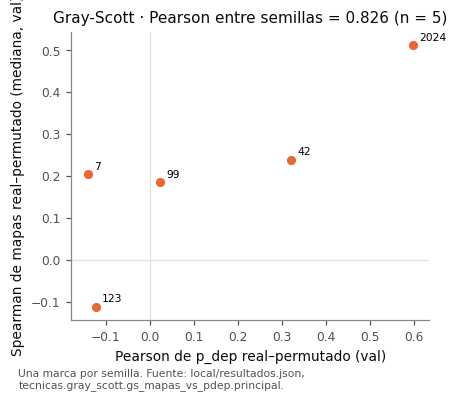

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f43_atribucion/figures/f43_09_gray_scott_mapas_vs_pdep.png')

In [14]:
G = R['tecnicas']['gray_scott']['gs_mapas_vs_pdep']['principal']
fig, ax = plt.subplots(figsize=(4.2, 3.4))
ax.scatter(G['corr_pdep'], G['corr_mapas'], color=style.TECH_COLOR['gray_scott'])
for s, a, b in zip(G['semillas'], G['corr_pdep'], G['corr_mapas']):
    ax.annotate(str(s), (a, b), xytext=(4, 3), textcoords='offset points', fontsize=style.FONT_SIZES['annot'])
ax.axhline(0, color=style.GRID, lw=0.8); ax.axvline(0, color=style.GRID, lw=0.8)
ax.set(xlabel='Pearson de p_dep real–permutado (val)', ylabel='Spearman de mapas real–permutado (mediana, val)',
       title=f"Gray-Scott · Pearson entre semillas = {G['pearson_entre_semillas']:.3f} (n = {G['n']})")
pie(fig, 'Una marca por semilla. Fuente: local/resultados.json, tecnicas.gray_scott.gs_mapas_vs_pdep.principal.')
guardar(fig, 'f43_09_gray_scott_mapas_vs_pdep', 'Gray-Scott, correlación de mapas frente a la de p_dep por semilla')

## 7. Ablación espectral (`val`)

ΔF1 = F1-val filtrado − F1-val sin filtrar, media de las 5 semillas (marcas tenues: semillas). Paso-bajo gaussiano con σ ∈ {1, 2, 4, 8} px sobre la imagen de 256 px; paso-alto = imagen − paso-bajo + media, con recorte y redondeo a [0, 255] (`ablacion_rango = recortar_redondear`; la fracción de píxeles recortados está en la tabla).

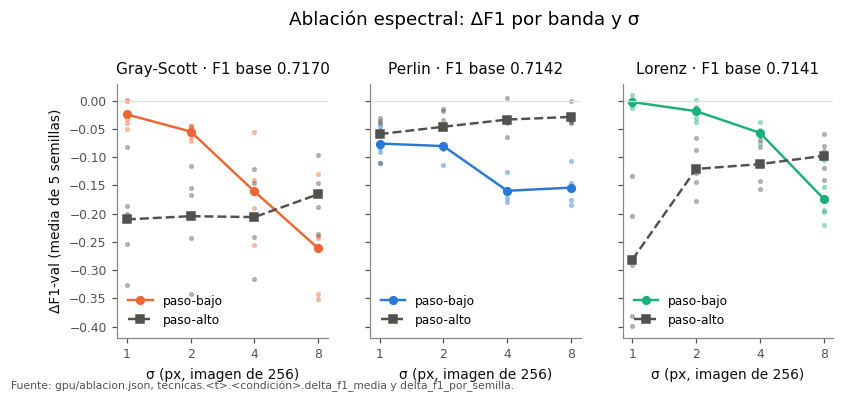

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f43_atribucion/figures/f43_10_ablacion_delta_f1.png')

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3.0), sharey=True)
sig = [1, 2, 4, 8]
for ax, t in zip(axes, TECHS):
    x = ABL['tecnicas'][t]
    for banda, ls, mk in (('paso_bajo', '-', 'o'), ('paso_alto', '--', 's')):
        med = [x[f'{banda}_s{s}']['delta_f1_media'] for s in sig]
        for s in sig:
            ax.scatter([s] * 5, list(x[f'{banda}_s{s}']['delta_f1_por_semilla'].values()), s=6,
                       color=style.TECH_COLOR[t] if banda == 'paso_bajo' else style.INK_SECONDARY, alpha=0.35)
        ax.plot(sig, med, ls=ls, marker=mk, color=style.TECH_COLOR[t] if banda == 'paso_bajo' else style.INK_SECONDARY,
                label=banda.replace('_', '-'))
        for s, m in zip(sig, med):
            assert canon_val(f'f43.{t}.ablacion.{banda}.s{s}.delta_f1') == m
    ax.axhline(0, color=style.GRID, lw=0.8)
    ax.set_xscale('log', base=2); ax.set_xticks(sig); ax.set_xticklabels(sig)
    ax.set(xlabel='σ (px, imagen de 256)', title=f"{style.TECH_LABEL[t]} · F1 base {x['original']['f1_media']:.4f}")
    ax.legend(loc='lower left')
axes[0].set_ylabel('ΔF1-val (media de 5 semillas)')
fig.suptitle('Ablación espectral: ΔF1 por banda y σ', y=1.1)
pie(fig, 'Fuente: gpu/ablacion.json, tecnicas.<t>.<condición>.delta_f1_media y delta_f1_por_semilla.')
guardar(fig, 'f43_10_ablacion_delta_f1', 'Ablación espectral, ΔF1-val por banda y σ')

In [16]:
rows = []
for t in TECHS:
    for cond, c in ABL['tecnicas'][t].items():
        rows.append({'técnica': style.TECH_LABEL[t], 'condición': cond, 'F1-val (media)': c['f1_media'],
                     'ΔF1 (media)': c['delta_f1_media'], 'ΔF1 mín. semilla': min(c['delta_f1_por_semilla'].values()),
                     'ΔF1 máx. semilla': max(c['delta_f1_por_semilla'].values()), 'fracción recortada': c['frac_recortada_media']})
pd.DataFrame(rows)

,técnica,condición,F1-val (media),ΔF1 (media),ΔF1 mín. semilla,ΔF1 máx. semilla,fracción recortada
0,Gray-Scott,original,0.717030,0.000000,0.000000,0.000000,0.000000
1,Gray-Scott,paso_bajo_s1,0.692686,-0.024344,-0.051014,0.001585,0.000000
2,Gray-Scott,paso_bajo_s2,0.662386,-0.054644,-0.072248,-0.044901,0.000000
3,Gray-Scott,paso_bajo_s4,0.556235,-0.160795,-0.255159,-0.054712,0.000000
4,Gray-Scott,paso_bajo_s8,0.455557,-0.261473,-0.351436,-0.130705,0.000000
5,Gray-Scott,paso_alto_s1,0.506861,-0.210169,-0.326953,-0.082607,0.002039
6,Gray-Scott,paso_alto_s2,0.512525,-0.204505,-0.341955,-0.115936,0.046991
7,Gray-Scott,paso_alto_s4,0.510943,-0.206087,-0.315154,-0.121415,0.149884
8,Gray-Scott,paso_alto_s8,0.551428,-0.165602,-0.235286,-0.096067,0.166214
9,Perlin,original,0.714216,0.000000,0.000000,0.000000,0.000000


## 8. Fracción de mapas constantes

Un mapa es constante si su rango es 0 (Grad-CAM nulo, F3.7 H5). Fracción agrupada sobre las 5 semillas (570 mapas por split: `umbral_constantes_unidad = agrupado`), por clase real y por clase predicha. `val` principal; prueba, réplica.

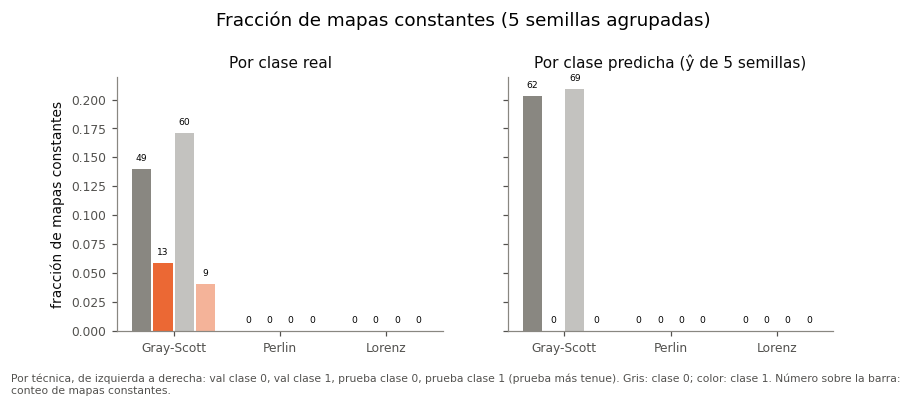

,técnica,clase,val,fracción val,prueba,fracción prueba
0,Gray-Scott,real 0,49/350,0.140000,60/350,0.171429
1,Gray-Scott,real 1,13/220,0.059091,9/220,0.040909
2,Gray-Scott,predicha 0,62/305,0.203279,69/330,0.209091
3,Gray-Scott,predicha 1,0/265,0.000000,0/240,0.000000
4,Perlin,real 0,0/350,0.000000,0/350,0.000000
5,Perlin,real 1,0/220,0.000000,0/220,0.000000
6,Perlin,predicha 0,0/290,0.000000,0/310,0.000000
7,Perlin,predicha 1,0/280,0.000000,0/260,0.000000
8,Lorenz,real 0,0/350,0.000000,0/350,0.000000
9,Lorenz,real 1,0/220,0.000000,0/220,0.000000


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.0), sharey=True)
w = 0.2
for ax, clase in zip(axes, ('real', 'predicha')):
    for i, t in enumerate(TECHS):
        for j, (sp, nsp) in enumerate((('val', 'val'), ('test', 'prueba'))):
            for y in (0, 1):
                f = CANON[f'f43.{t}.constantes.clase_{clase}.y{y}.fraccion']['value'][sp]
                xpos = i + (2 * j + y - 1.5) * w
                ax.bar(xpos, f, width=w * 0.9, color=style.TECH_COLOR[t] if y == 1 else style.MUTED,
                       alpha=1.0 if sp == 'val' else 0.5, edgecolor='none')
                k = CANON[f'f43.{t}.constantes.clase_{clase}.y{y}.{nsp}.n_constantes']['value']
                ax.text(xpos, f + 0.005, str(k), ha='center', va='bottom', fontsize=style.FONT_SIZES['annot'] - 1)
    ax.set_xticks(range(3)); ax.set_xticklabels([style.TECH_LABEL[t] for t in TECHS])
    ax.set_title(f'Por clase {clase}' + (' (ŷ de 5 semillas)' if clase == 'predicha' else ''))
axes[0].set_ylabel('fracción de mapas constantes')
fig.suptitle('Fracción de mapas constantes (5 semillas agrupadas)', y=1.08)
pie(fig, 'Por técnica, de izquierda a derecha: val clase 0, val clase 1, prueba clase 0, prueba clase 1 (prueba más tenue). '
         'Gris: clase 0; color: clase 1. Número sobre la barra: conteo de mapas constantes.')
guardar(fig, 'f43_11_fraccion_constantes', 'Fracción de mapas constantes por clase real y predicha')
rows = []
for t in TECHS:
    for clase in ('real', 'predicha'):
        for y in (0, 1):
            b = f'f43.{t}.constantes.clase_{clase}.y{y}'
            rows.append({'técnica': style.TECH_LABEL[t], 'clase': f'{clase} {y}',
                         'val': f"{CANON[b + '.val.n_constantes']['value']}/{CANON[b + '.val.n_mapas']['value']}",
                         'fracción val': CANON[b + '.fraccion']['value']['val'],
                         'prueba': f"{CANON[b + '.prueba.n_constantes']['value']}/{CANON[b + '.prueba.n_mapas']['value']}",
                         'fracción prueba': CANON[b + '.fraccion']['value']['test']})
pd.DataFrame(rows)

## 9. Figuras generadas

In [18]:
pd.DataFrame(FIGS)

,archivo,figura
0,results/f43_atribucion/figures/f43_01_mapas_medios_val.png,"Mapas medios por clase real y diferencia, val (principal)"
1,results/f43_atribucion/figures/f43_02_mapas_medios_prueba_replica.png,"Mapas medios por clase real y diferencia, prueba (réplica, G1)"
2,results/f43_atribucion/figures/f43_03_mapas_medios_predicha_val.png,"Mapas medios por clase predicha, val"
3,results/f43_atribucion/figures/f43_04_backbone_por_clase_val.png,"Atención del backbone ViT por clase real, val"
4,results/f43_atribucion/figures/f43_05_gray_scott_perfil_radial.png,"Gray-Scott, perfil radial por clase real"
5,results/f43_atribucion/figures/f43_06_lorenz_terciles_u4.png,"Lorenz, mapas por tercil de u4, val"
6,results/f43_atribucion/figures/f43_07_cascada_por_paso.png,"Cascada de cordura por paso, Spearman 56 × 56, con banda de semillas reales"
7,results/f43_atribucion/figures/f43_08_cosenos_cabezas.png,Cosenos de cabezas ViT real–permutada con referencia de 10 pares
8,results/f43_atribucion/figures/f43_09_gray_scott_mapas_vs_pdep.png,"Gray-Scott, correlación de mapas frente a la de p_dep por semilla"
9,results/f43_atribucion/figures/f43_10_ablacion_delta_f1.png,"Ablación espectral, ΔF1-val por banda y σ"
